## Clusteren met k-Means

Clusteren = het verdelen van je dataset in verschillende groepen op basis van verschillende eigenschappen van je data.

We gaan data clusteren met behulp van het k-Means algoritme.
Daarvoor lezen we eerst de benodigde libraries in.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

!pip install kmodes
!pip install kneed
from kmodes.kmodes import KModes
from kneed import KneeLocator
from sklearn.cluster import KMeans
from sklearn.datasets import make_blobs

# Voorbeeld 1 Blobs
Nu creeren we een dataset waarmee we het clusteren gaan oefenen.

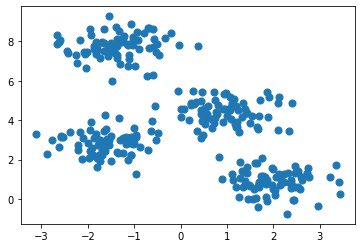

In [ ]:
X, y_true = make_blobs(n_samples=300, centers=4, cluster_std=0.60, random_state=0)
plt.scatter(X[:,0], X[:,1], s=50)

We zien dat er 4 clusters lijken te zijn.<br>
Het algoritme bevestigt dat: zie plaatje met de (in kleur) voorspelde clustering van de punten.

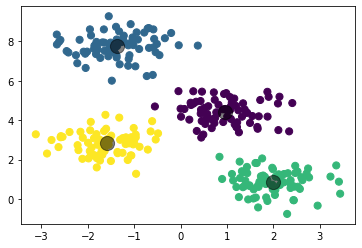

In [ ]:
kmeans= KMeans(n_clusters=4)
kmeans.fit(X)
y_kmeans = kmeans.predict(X)

plt.scatter(X[:,0],X[:,1], c=y_kmeans, s=50, cmap='viridis')
centers = kmeans.cluster_centers_
plt.scatter(centers[:,0],centers[:,1], c='black', s=200, alpha=0.5)

# Voorbeeld 2: Pinguins
Via panda's wordt het bestand penguins_size.csv ingelezen.

De NaN's worden uit de dataframe gehaald omdat er geen waarden zijn die ingevuld kunnen worden die een nuttige uitkomst geven.


In [ ]:
# =====================Inladen bestanden=======================================
# Tabellen met parameters ophalen uit dit bestand.
df = pd.read_csv("penguins_size.csv")
# =============================================================================
df = df.dropna()
df

,species,island,culmen_length_mm,culmen_depth_mm,flipper_length_mm,body_mass_g,sex
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,MALE
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,FEMALE
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,FEMALE
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,FEMALE
5,Adelie,Torgersen,39.3,20.6,190.0,3650.0,MALE
...,...,...,...,...,...,...,...
338,Gentoo,Biscoe,47.2,13.7,214.0,4925.0,FEMALE
340,Gentoo,Biscoe,46.8,14.3,215.0,4850.0,FEMALE
341,Gentoo,Biscoe,50.4,15.7,222.0,5750.0,MALE
342,Gentoo,Biscoe,45.2,14.8,212.0,5200.0,FEMALE


In [ ]:
df.describe()

,culmen_length_mm,culmen_depth_mm,flipper_length_mm,body_mass_g
count,334.000000,334.000000,334.000000,334.000000
mean,43.994311,17.160479,201.014970,4209.056886
std,5.460521,1.967909,14.022175,804.836129
min,32.100000,13.100000,172.000000,2700.000000
25%,39.500000,15.600000,190.000000,3550.000000
50%,44.500000,17.300000,197.000000,4050.000000
75%,48.575000,18.700000,213.000000,4793.750000
max,59.600000,21.500000,231.000000,6300.000000


In onderstaand scatterplot wordt de lengte en 'diepte' van de snavel tegen elkaar uitgezet.

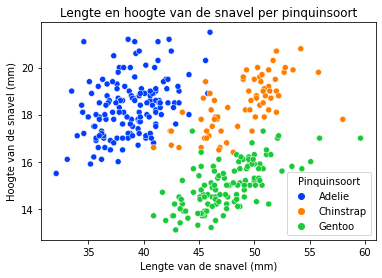

In [ ]:
sns.set_palette("bright")
ax = sns.scatterplot(x='culmen_length_mm',
                     y='culmen_depth_mm',
                     data=df,
                     hue='species')
plt.title('Lengte en hoogte van de snavel per pinquinsoort', color='black')
plt.xlabel('Lengte van de snavel (mm)')
plt.ylabel('Hoogte van de snavel (mm)')
plt.legend(title='Pinquinsoort')
plt.show()

In de scatterplot zien we duidelijke groepen van verschillende soorten pinguins met een bepaalde combinatie van lengte en hoogte ('diepte'). Deze 2 variabelen zouden een goed voorspellingsmodel kunnen maken.

## K-Means clustering
Er lijken 3 clusters te zijn. Dit is ook hierboven te zien. Inclusief enkele uitschieters kunnen we de scatterplots goed indelen per pinguinsoort.

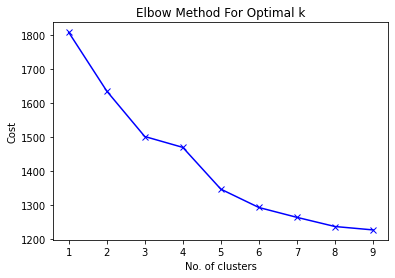

5

In [ ]:
cost = []
K = range(1,10)
for num_clusters in list(K):
  kmode = KModes(n_clusters = num_clusters, verbose = False)
  kmode.fit_predict(df)
  cost.append(kmode.cost_)

plt.plot(K, cost, 'bx-')
plt.xlabel('No. of clusters')
plt.ylabel('Cost')
plt.title('Elbow Method For Optimal k')
plt.show()

kl = KneeLocator(range(1, 10), cost,
                 curve = "convex",
                 direction = "decreasing")
kl.elbow

Uit kmodes clustering blijkt dat er 3 of 5 clusters in de data zitten. Deze gaan we onderstaand verder uitwerken.

In [ ]:
kmode = KModes(n_clusters=5, init = "random", n_init = 3, verbose=False)
clusters = kmode.fit_predict(df)
unique, counts = np.unique(kmode.labels_, return_counts=True)
dict(zip(unique, counts))

{0: 81, 1: 100, 2: 43, 3: 72, 4: 38}

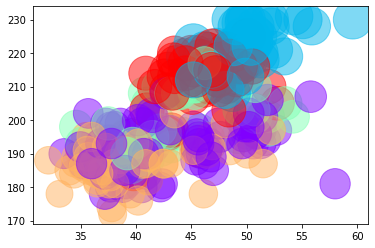

In [ ]:
x = df.iloc[:,2:6]
kmeans = KMeans(5)
kmeans.fit(x)
identified_clusters = kmeans.fit_predict(x)
data_with_clusters = df.copy()
data_with_clusters['Clusters'] = identified_clusters
plt.scatter(data_with_clusters['culmen_length_mm'],data_with_clusters['flipper_length_mm'],data_with_clusters['body_mass_g'], c = data_with_clusters['Clusters'], marker = '.', cmap = 'rainbow', alpha = 0.50)

Alhoewel uit de clusteringsmethode kwam dat er 5 clusters in de data zitten, zijn deze niet duidelijk zichtbaar wanneer deze voorspeld en gevisualiseerd worden. Wanneer we 3 clusters gebruiken zien we een duidelijkere verdeling. Dit is hoogstwaarschijnlijk omdat de clusters die we dan zien gelijkenissen hebben met de 3 soorten pinguins.

In [ ]:
kmode = KModes(n_clusters=3, init = "random", n_init = 3, verbose=False)
clusters = kmode.fit_predict(df)
unique, counts = np.unique(kmode.labels_, return_counts=True)
dict(zip(unique, counts))

{0: 105, 1: 93, 2: 136}

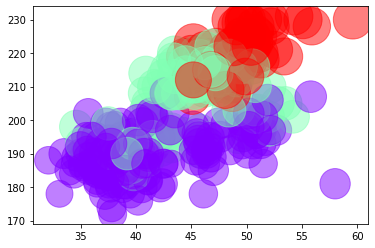

In [ ]:
x = df.iloc[:,2:6]
kmeans = KMeans(3)
kmeans.fit(x)
identified_clusters = kmeans.fit_predict(x)
data_with_clusters = df.copy()
data_with_clusters['Clusters'] = identified_clusters
plt.scatter(data_with_clusters['culmen_length_mm'],data_with_clusters['flipper_length_mm'],data_with_clusters['body_mass_g'],
            c = data_with_clusters['Clusters'], marker = '.', cmap = 'rainbow', alpha = 0.50)

# Voorbeeld 3 VU studentendataset
Nu kijken of we deze techniek kunnen toepassen op onze NUMERIEKE data.<br>

Eerst inlezen van een selectie (twee kolommen: income en bmi) van de data.

In [ ]:
df = pd.read_excel("vustudentanalytics.xlsx")
df['bmi_calc'] = df['weight'] / (df['height']/100)**2
df = df.loc[:, ["income", "bmi"]]
df.head() # We take a look at the first 5 rows of the dataset

,income,bmi
0,800.0,"30,79585"
1,350.0,"23,44934"
2,NaN,"18,36547"
3,900.0,"30,46875"
4,1500.0,"20,02884"


In [ ]:
df.shape

(5000, 2)

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 2 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   income    4317 non-null   float64
 1   bmi_calc  4947 non-null   float64
dtypes: float64(2)
memory usage: 78.2 KB


We zien dat er 5.000 regels in de dataset zitten, maar in zowel de income als de bmi-kolom ontbreken er waarden.<p>
Om k-Means uit te kunnen voeren, mogen er geen NULL of NaN waarden in de tabel zitten.<p>
Die gaan we dus eerst verwijderen.

In [ ]:
df_analyse = df.dropna()
df_analyse = df_analyse[df_analyse.income != -8]
df_analyse.info()

<class 'pandas.core.frame.DataFrame'>
Int64Index: 3684 entries, 0 to 4998
Data columns (total 2 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   income    3684 non-null   float64
 1   bmi_calc  3684 non-null   float64
dtypes: float64(2)
memory usage: 86.3 KB


We houden 3.684 regels over, daarmee gaan we nu clusteren.<p>
Onze hypothese is dat er 3 clusters in de data zitten:<br>
- 1 cluster met laag inkomen, hoge bmi<br>
- 1 cluster met gemiddeld inkomen en gemiddelde bmi<br>
- 1 cluster met hoog inkomen en lage bmi

In [ ]:
kmeans = KMeans(n_clusters=3, init = "random", n_init = 10, verbose=False)
clusters = kmeans.fit_predict(df_analyse)

We kunnen nu kijken hoeveel records er in ieder cluster zitten:

In [ ]:
unique, counts = np.unique(kmeans.labels_, return_counts=True)
dict(zip(unique, counts))

{0: 1067, 1: 2494, 2: 123}

We kunnen ook een nieuwe kolom met het clusternummer aan de tabel toevoegen:

In [ ]:
df_analyse.insert(0, "Cluster", clusters, True)
df_analyse.head()

,Cluster,income,bmi_calc
0,1,800.0,30.795848
1,1,350.0,23.449341
3,1,900.0,30.468750
4,1,1500.0,20.028842
6,0,2000.0,24.092971


Tot slot: hoe zien de clusters er nu uit?

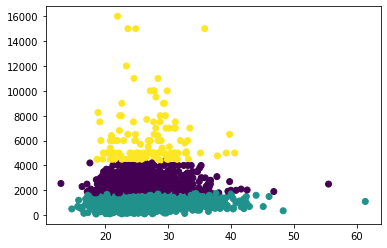

In [ ]:
plt.scatter(df_analyse['bmi_calc'],df_analyse['income'], c = df_analyse['Cluster'])

In [ ]:
a = pd.crosstab(df_analyse["Cluster"], df_analyse["bmi_calc"])
b = pd.crosstab(df_analyse["Cluster"], df_analyse["income"])
cluster_uitkomst = a.join(b)
cluster_uitkomst


,12.962963,14.692378,15.625000,15.780836,15.916955,16.161616,16.326531,16.608997,16.896235,16.901028,...,7700.000000,8000.000000,8255.000000,9000.000000,9500.000000,10000.000000,11000.000000,12000.000000,15000.000000,16000.000000
Cluster,,,,,,,,,,,,,,,,,,,,,
0,1,0,0,0,0,0,1,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,0,1,1,1,1,1,1,1,1,1,...,0,0,0,0,0,0,0,0,0,0
2,0,0,0,0,0,0,0,0,0,0,...,1,4,1,3,1,4,2,1,3,1


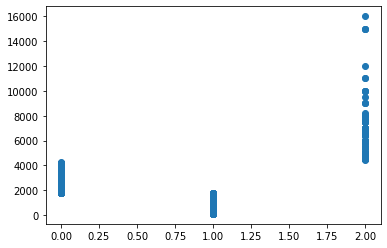

In [ ]:
plt.scatter(df_analyse['Cluster'],df_analyse['income'])

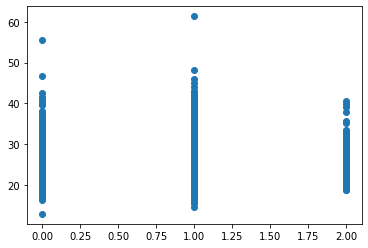

In [ ]:
plt.scatter(df_analyse['Cluster'],df_analyse['bmi_calc'])

In [ ]:
cluster_uitkomst.to_excel('cluster_uitkomst.xlsx', sheet_name='k-means clusters')

Grote Vraag: is dit nu zinvol? Hebben we iets aan deze clusteranalyse?

Niet vergeten: de nadelen van deze methode:<br>
- je moet zelf OP VOORHAND het aantal clusters opgeven dat je verwacht<br>
- er is geen garantie dat dit aantal clusters het optimale aantal clusters is<br>

# Extra: voorspellen met k-Means
We gaan de soort pinguin voorspellen op basis van de snavellengte en het gewicht.

In [4]:
from google.colab import drive
drive.mount('/content/drive', force_remount=True)

Mounted at /content/drive


In [5]:
rel_data_path = "/content/drive/MyDrive/penguins_size.csv"

In [6]:
data = pd.read_csv(rel_data_path)
data

,species,island,culmen_length_mm,culmen_depth_mm,flipper_length_mm,body_mass_g,sex
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,MALE
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,FEMALE
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,FEMALE
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,FEMALE
...,...,...,...,...,...,...,...
339,Gentoo,Biscoe,NaN,NaN,NaN,NaN,NaN
340,Gentoo,Biscoe,46.8,14.3,215.0,4850.0,FEMALE
341,Gentoo,Biscoe,50.4,15.7,222.0,5750.0,MALE
342,Gentoo,Biscoe,45.2,14.8,212.0,5200.0,FEMALE


Er zitten nog NaN's in de data, die verwijderen we:

In [9]:
data = data.dropna()
data

,species,island,culmen_length_mm,culmen_depth_mm,flipper_length_mm,body_mass_g,sex
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,MALE
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,FEMALE
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,FEMALE
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,FEMALE
5,Adelie,Torgersen,39.3,20.6,190.0,3650.0,MALE
...,...,...,...,...,...,...,...
338,Gentoo,Biscoe,47.2,13.7,214.0,4925.0,FEMALE
340,Gentoo,Biscoe,46.8,14.3,215.0,4850.0,FEMALE
341,Gentoo,Biscoe,50.4,15.7,222.0,5750.0,MALE
342,Gentoo,Biscoe,45.2,14.8,212.0,5200.0,FEMALE


We voorspellen met de k-Nearest Neighbor Classifier:

In [30]:
from sklearn.neighbors import KNeighborsClassifier

predictors = ['culmen_length_mm', 'body_mass_g']
outcome = 'species'

newpenguin = data.loc[0:0, predictors]
X = data.loc[1:, predictors]
y = data.loc[1:, outcome]

knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(X, y)
print(knn.predict(newpenguin))
print(knn.predict_proba(newpenguin))

nbrs = knn.kneighbors(newpenguin)
print(X.iloc[nbrs[1][0], :])

['Adelie']
[[0.8 0.2 0. ]]
     culmen_length_mm  body_mass_g
106              38.6       3750.0
149              37.8       3750.0
59               37.6       3750.0
159              51.3       3750.0
143              40.7       3725.0


We gebruiken de eerste regel uit de data als te voorspellen waarde. Met 80% waarschijnlijkheid is het een Adelie, 20% kans dat het een Chinstrap is, 0% dat het een Gentoo is (volgens dit model).
<p>
We zien verder de 5 'buren' op basis waarvan deze voorspelling gemaakt is.<br>Wat opvalt: de snavellengte varieert bij de buren, het gewicht nauwelijks. Kennelijk gebruikt het model vooral het gewicht om de voorspelling te maken.

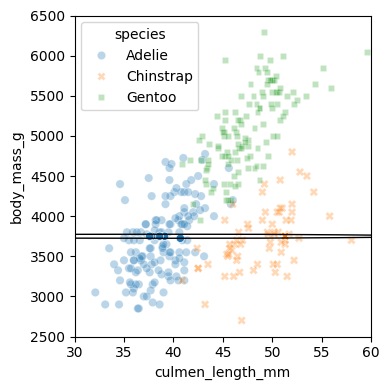

In [35]:
from matplotlib.patches import Ellipse

nbrs = knn.kneighbors(newpenguin)
maxDistance = np.max(nbrs[0][0])

fig, ax = plt.subplots(figsize=(4, 4))
sns.scatterplot(x='culmen_length_mm', y='body_mass_g', style='species',
                hue='species', data=data, alpha=0.3, ax=ax)

# Correctly retrieve the neighbor rows from the original data DataFrame
neighbor_rows = data.loc[X.index[nbrs[1][0]], :]

sns.scatterplot(x='culmen_length_mm', y='body_mass_g', style='species',
                hue='species',
                data=pd.concat([newpenguin.assign(species=data.loc[0,'species']), neighbor_rows]),
                ax=ax, legend=False)
ellipse = Ellipse(xy=newpenguin.values[0],
                  width=2 * maxDistance, height=2 * maxDistance,
                  edgecolor='black', fc='None', lw=1)
ax.add_patch(ellipse)
ax.set_xlim(30, 60) # Adjusted limits for penguin data
ax.set_ylim(2500, 6500) # Adjusted limits for penguin data

plt.tight_layout()
plt.show()

Het plaatje bevestigt dat vooral gewicht als voorspeller gebruikt wordt: alleen punten binnen de (nogal afgeplatte) cirkel (ellips) worden gebruikt bij de voorspelling.

Als we dit 'schaal'probleem willen oplossen (absolute waarden van gewicht (in grammen) zijn vele malen groter dan de lengte van de snavel (in mm), moeten we alle waarden van de variabelen op dezelfde schaal brengen:

In [40]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn import preprocessing

predictors = ['culmen_length_mm', 'body_mass_g']
outcome = 'species'

newpenguin = data.loc[0:0, predictors]
X = data.loc[1:, predictors]
y = data.loc[1:, outcome]

scaler = preprocessing.StandardScaler()
scaler.fit(X * 1.0)

X_std = scaler.transform(X * 1.0)
newpenguin_std = scaler.transform(newpenguin * 1.0)

knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(X_std, y)

print(knn.predict(newpenguin_std))
print(knn.predict_proba(newpenguin_std))

nbrs = knn.kneighbors(newpenguin_std)
print(X.iloc[nbrs[1][0], :])

['Adelie']
[[1. 0. 0.]]
     culmen_length_mm  body_mass_g
24               38.8       3800.0
106              38.6       3750.0
1                39.5       3800.0
13               38.6       3800.0
145              39.0       3650.0


Nu is er zowel bij de snavellengte als bij het gewicht meer variatie in de 'buur'waarden.

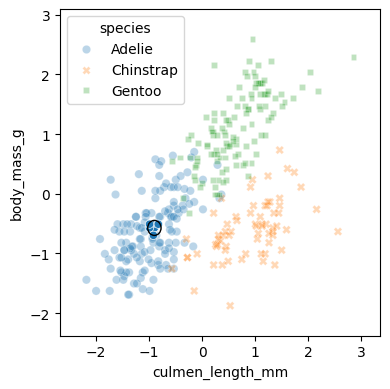

In [41]:
maxDistance = np.max(nbrs[0][0])

fig, ax = plt.subplots(figsize=(4, 4))

# Scale the entire 'data' dataframe's predictor columns for consistent plotting
data_plot_scaled = data.copy()
data_plot_scaled[predictors] = scaler.transform(data_plot_scaled[predictors])

sns.scatterplot(x='culmen_length_mm', y='body_mass_g', style='species',
                hue='species', data=data_plot_scaled, alpha=0.3, ax=ax)

# Correctly retrieve the neighbor rows from the original data DataFrame (unscaled initially)
# X.index[nbrs[1][0]] gives the original DataFrame indices for the neighbors in X_std
original_neighbor_rows = data.loc[X.index[nbrs[1][0]], :]

# Scale the features of the neighbor rows
neighbor_rows_scaled_for_plot = original_neighbor_rows.copy()
neighbor_rows_scaled_for_plot[predictors] = scaler.transform(neighbor_rows_scaled_for_plot[predictors])

# Convert newpenguin_std (numpy array) to DataFrame and add species for plotting
newpenguin_plot_scaled = pd.DataFrame(newpenguin_std, columns=predictors, index=newpenguin.index)
newpenguin_plot_scaled['species'] = data.loc[newpenguin.index[0], 'species']

sns.scatterplot(x='culmen_length_mm', y='body_mass_g', style='species',
                hue='species',
                data=pd.concat([newpenguin_plot_scaled, neighbor_rows_scaled_for_plot]),
                ax=ax, legend=False)

ellipse = Ellipse(xy=newpenguin_std[0], # Use scaled coordinates for the ellipse center, newpenguin_std is an array
                  width=2 * maxDistance, height=2 * maxDistance,
                  edgecolor='black', fc='None', lw=1)
ax.add_patch(ellipse)

# Adjust limits for the scaled data.
min_x_scaled, max_x_scaled = data_plot_scaled['culmen_length_mm'].min(), data_plot_scaled['culmen_length_mm'].max()
min_y_scaled, max_y_scaled = data_plot_scaled['body_mass_g'].min(), data_plot_scaled['body_mass_g'].max()
ax.set_xlim(min_x_scaled - 0.5, max_x_scaled + 0.5)
ax.set_ylim(min_y_scaled - 0.5, max_y_scaled + 0.5)


plt.tight_layout()
plt.show()

De voorspelling wordt er overigens in dit voorbeeld niet beter op:<br>
de werkelijke waarde is Chinstrap, de voorspelling is (met 100% waarschijnlijkheid!) Adeloo. Gewicht 'weegt' toch nog te zwaar lijkt het, je zou misschien de snavellengte meer mee moeten wegen in de voorspelling

### Model Evaluatie met een Train-Test Split

In [37]:
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.preprocessing import StandardScaler

# Prepare the full dataset for splitting, including dropping NaNs
df_full = data.dropna().copy()
X_full = df_full[predictors]
y_full = df_full[outcome]

# Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X_full, y_full, test_size=0.3, random_state=42, stratify=y_full)

# Scale the features using StandardScaler
scaler_eval = StandardScaler()
X_train_scaled = scaler_eval.fit_transform(X_train)
X_test_scaled = scaler_eval.transform(X_test)

# Train the KNN model on the scaled training data
knn_eval = KNeighborsClassifier(n_neighbors=5) # Using the same n_neighbors as in the prediction example
knn_eval.fit(X_train_scaled, y_train)

# Make predictions on the scaled test data
y_pred = knn_eval.predict(X_test_scaled)

# Generate and print the classification report and confusion matrix
print("\nClassification Report:")
print(classification_report(y_test, y_pred))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))


Classification Report:
              precision    recall  f1-score   support

      Adelie       0.95      0.89      0.92        44
   Chinstrap       0.88      1.00      0.93        21
      Gentoo       0.92      0.92      0.92        36

    accuracy                           0.92       101
   macro avg       0.91      0.93      0.92       101
weighted avg       0.92      0.92      0.92       101


Confusion Matrix:
[[39  2  3]
 [ 0 21  0]
 [ 2  1 33]]


De output van het classificatierapport en de verwarringsmatrix geeft je inzicht in hoe goed het model presteert op onzichtbare data en hoe betrouwbaar het is in het classificeren van verschillende pinguïnsoorten.

### Optimaliseren van de k-waarde met GridSearchCV

Dit zal de `k`-waarde vinden die de beste nauwkeurigheid oplevert via 5-voudige cross-validatie op de trainingsgegevens. Vervolgens wordt het model met deze optimale `k`-waarde geëvalueerd op de testset.

In [38]:
from sklearn.model_selection import GridSearchCV

# Define the parameter grid to search
param_grid = {'n_neighbors': np.arange(1, 30)} # Test k from 1 to 29

# Create a KNN classifier instance
knn_optimizer = KNeighborsClassifier()

# Create the GridSearchCV object
# cv=5 means 5-fold cross-validation
# scoring='accuracy' means we optimize for accuracy
grid_search = GridSearchCV(knn_optimizer, param_grid, cv=5, scoring='accuracy', verbose=1)

# Fit the GridSearchCV to the scaled training data
# X_train_scaled and y_train are from the previous train-test split cell (7fefdfc1)
grid_search.fit(X_train_scaled, y_train)

# Print the best k-value found
print(f"\nBest k-value: {grid_search.best_params_['n_neighbors']}")

# Print the best score achieved with that k-value
print(f"Best cross-validation accuracy: {grid_search.best_score_:.4f}")

# You can also access the best model directly
best_knn_model = grid_search.best_estimator_

# Evaluate the best model on the test set
y_pred_best = best_knn_model.predict(X_test_scaled)
print("\nClassification Report with optimal k-value:")
print(classification_report(y_test, y_pred_best))

print("\nConfusion Matrix with optimal k-value:")
print(confusion_matrix(y_test, y_pred_best))

Fitting 5 folds for each of 29 candidates, totalling 145 fits

Best k-value: 5
Best cross-validation accuracy: 0.9614

Classification Report with optimal k-value:
              precision    recall  f1-score   support

      Adelie       0.95      0.89      0.92        44
   Chinstrap       0.88      1.00      0.93        21
      Gentoo       0.92      0.92      0.92        36

    accuracy                           0.92       101
   macro avg       0.91      0.93      0.92       101
weighted avg       0.92      0.92      0.92       101


Confusion Matrix with optimal k-value:
[[39  2  3]
 [ 0 21  0]
 [ 2  1 33]]


### Optimaliseren van meerdere KNN-hyperparameters

Deze code zal een uitgebreide zoektocht uitvoeren naar de beste combinatie van `n_neighbors`, `weights`, en `metric`. De output toont de optimale parameters en de prestaties van het model met deze parameters op de testset.

In [39]:
from sklearn.model_selection import GridSearchCV
from sklearn.neighbors import KNeighborsClassifier
import numpy as np

# Define a more extensive parameter grid to search
param_grid_extended = {
    'n_neighbors': np.arange(1, 15), # Test k from 1 to 14
    'weights': ['uniform', 'distance'], # How neighbors are weighted
    'metric': ['euclidean', 'manhattan'] # Distance metric to use
}

# Create a KNN classifier instance
knn_optimizer_extended = KNeighborsClassifier()

# Create the GridSearchCV object
# cv=5 means 5-fold cross-validation
# scoring='accuracy' means we optimize for accuracy
grid_search_extended = GridSearchCV(knn_optimizer_extended, param_grid_extended, cv=5, scoring='accuracy', verbose=1, n_jobs=-1) # n_jobs=-1 uses all available CPU cores

# Fit the GridSearchCV to the scaled training data
# X_train_scaled and y_train are from the previous train-test split cell (7fefdfc1)
grid_search_extended.fit(X_train_scaled, y_train)

# Print the best parameters found
print(f"\nBest parameters found: {grid_search_extended.best_params_}")

# Print the best score achieved with those parameters
print(f"Best cross-validation accuracy with optimized hyperparameters: {grid_search_extended.best_score_:.4f}")

# You can also access the best model directly
best_knn_model_extended = grid_search_extended.best_estimator_

# Evaluate the best model on the test set
y_pred_best_extended = best_knn_model_extended.predict(X_test_scaled)
print("\nClassification Report with optimal hyperparameters:")
print(classification_report(y_test, y_pred_best_extended))

print("\nConfusion Matrix with optimal hyperparameters:")
print(confusion_matrix(y_test, y_pred_best_extended))

Fitting 5 folds for each of 56 candidates, totalling 280 fits

Best parameters found: {'metric': 'euclidean', 'n_neighbors': np.int64(5), 'weights': 'uniform'}
Best cross-validation accuracy with optimized hyperparameters: 0.9614

Classification Report with optimal hyperparameters:
              precision    recall  f1-score   support

      Adelie       0.95      0.89      0.92        44
   Chinstrap       0.88      1.00      0.93        21
      Gentoo       0.92      0.92      0.92        36

    accuracy                           0.92       101
   macro avg       0.91      0.93      0.92       101
weighted avg       0.92      0.92      0.92       101


Confusion Matrix with optimal hyperparameters:
[[39  2  3]
 [ 0 21  0]
 [ 2  1 33]]


# Extra: feature-engineering met k-Means

De functie cross_val_predict van scikit-learn is een handige tool die het volgende doet:
<p>
<b>Cross-validatie:</b> Het voert cross-validatie uit, vergelijkbaar met cross_val_score of cross_validate. Dit betekent dat de dataset wordt opgedeeld in meerdere 'folds' (bijvoorbeeld 5, zoals in de code).<br>
<b>Voorspellingen:</b> In plaats van een score (zoals nauwkeurigheid) per fold te retourneren, retourneert cross_val_predict een voorspelling voor elk datapunt in de originele dataset.<br>
<b>'Out-of-fold' voorspellingen:</b> Het cruciale aspect is dat voor elk datapunt de voorspelling wordt gedaan door een model dat dat specifieke datapunt niet heeft gebruikt tijdens zijn trainingsfase. Dus, als je 5 folds hebt, wordt een datapunt uit fold 1 voorspeld door een model dat getraind is op folds 2, 3, 4 en 5. Dit wordt 'out-of-fold' voorspellen genoemd.<br>
<b>Voorkomen van data-lekkage:</b> Dit is essentieel voor het voorkomen van data-lekkage. Als je bijvoorbeeld een nieuwe feature wilt creëren op basis van modelvoorspellingen, wil je niet dat het model informatie 'ziet' van de data die het later moet voorspellen. Door 'out-of-fold' voorspellingen te gebruiken, creëer je een set van voorspellingen die op een eerlijke manier zijn gegenereerd, alsof ze van een volledig onzichtbare dataset komen.
<p>
Kortom, cross_val_predict geeft je een set voorspellingen voor je hele dataset, waarbij elke voorspelling is gedaan door een model dat het betreffende datapunt nog nooit eerder heeft gezien. Dit maakt het ideaal voor taken zoals het genereren van meta-features voor stacking-modellen, of zoals in jouw geval, het creëren van een robuuste 'voorspelde soort' als nieuwe feature.

### Nieuwe Feature met KNN: Voorspelde Pinguïnsoort

In [3]:
from sklearn.model_selection import cross_val_predict
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler
import pandas as pd
from google.colab import drive

# Mount Google Drive to ensure access to the file
drive.mount('/content/drive', force_remount=True)

# Re-load data, predictors, and outcome to ensure they are defined in this cell's context
rel_data_path = "/content/drive/MyDrive/penguins_size.csv"
data = pd.read_csv(rel_data_path)

predictors = ['culmen_length_mm', 'body_mass_g']
outcome = 'species'

df_full = data.dropna().copy() # Make sure to start with a fresh, cleaned copy
X_full = df_full[predictors]
y_full = df_full[outcome]

scaler_for_feature = StandardScaler() # Create a new scaler for this operation
X_full_scaled = scaler_for_feature.fit_transform(X_full)

# Initialize KNN model with the best hyperparameters found previously
best_knn = KNeighborsClassifier(
    n_neighbors=5, # From GridSearchCV output
    weights='uniform', # From GridSearchCV output
    metric='euclidean' # From GridSearchCV output
)

# Generate out-of-fold predictions for the entire dataset
# This creates a new 'predicted_species' feature that avoids data leakage.
predicted_species_feature = cross_val_predict(best_knn, X_full_scaled, y_full, cv=5, n_jobs=-1)

# Add the new feature to a copy of the full DataFrame
df_with_predicted_species = df_full.copy()
df_with_predicted_species['predicted_species'] = predicted_species_feature

# Display the DataFrame with the new feature
print("DataFrame with new 'predicted_species' feature (first 10 rows):")
display(df_with_predicted_species.head(10))

# You can also check the accuracy of this new feature against the actual species
from sklearn.metrics import accuracy_score
overall_accuracy = accuracy_score(df_with_predicted_species['species'], df_with_predicted_species['predicted_species'])
print(f"\nOverall accuracy of the predicted_species feature: {overall_accuracy:.4f}")

Mounted at /content/drive
DataFrame with new 'predicted_species' feature (first 10 rows):


,species,island,culmen_length_mm,culmen_depth_mm,flipper_length_mm,body_mass_g,sex,predicted_species
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,MALE,Adelie
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,FEMALE,Adelie
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,FEMALE,Adelie
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,FEMALE,Adelie
5,Adelie,Torgersen,39.3,20.6,190.0,3650.0,MALE,Adelie
6,Adelie,Torgersen,38.9,17.8,181.0,3625.0,FEMALE,Adelie
7,Adelie,Torgersen,39.2,19.6,195.0,4675.0,MALE,Adelie
12,Adelie,Torgersen,41.1,17.6,182.0,3200.0,FEMALE,Adelie
13,Adelie,Torgersen,38.6,21.2,191.0,3800.0,MALE,Adelie
14,Adelie,Torgersen,34.6,21.1,198.0,4400.0,MALE,Adelie



Overall accuracy of the predicted_species feature: 0.9341
